In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
from datasets import Dataset

c:\Users\User\miniconda3\envs\torch_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Update the configuration for 5-class classification
DATA_XLSX = "dataset/dataset2.xlsx"
TEXT_COL = "text"
POLARITY_COL = "label"  # Changed from "polarity" to "label"
MAX_LEN = 160
OUT_DIR = "outputs"
MODEL_NAME = "BAAI/bge-m3"  # Changed to BG-M3 model
NUM_LABELS = 5  # Changed from 2 to 5

# Class labels mapping
CLASS_LABELS = {
    0: "General",
    1: "No Sarcasm", 
    2: "Hate Speech",
    3: "GeoPolitics",
    4: "Sports/Entertainment"
}

# Hyperparameters
HPARAMS = {
    "learning_rate": 2e-5,
    "batch_size": 16,
    "epochs": 30
}

In [3]:
def ensure_dir(path):
    os.makedirs(path, exist_ok=True)

def plot_cm(y_true, y_pred, classes, path):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(10, 8))  # Increased size for 5x5 matrix
    plt.imshow(cm, cmap=plt.cm.Blues)
    plt.title("Stage 1 Confusion Matrix - 5 Class Classification")
    plt.colorbar()
    
    # Use class names instead of numbers
    class_names = [CLASS_LABELS[i] for i in range(len(classes))]
    plt.xticks(range(len(classes)), class_names, rotation=45, ha='right')
    plt.yticks(range(len(classes)), class_names)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    
    # Add text annotations
    for i in range(len(classes)):
        for j in range(len(classes)):
            plt.text(j, i, cm[i,j], ha="center", va="center", 
                    color="white" if cm[i,j] > cm.max()/2 else "black")
    plt.tight_layout()
    plt.savefig(path, dpi=300, bbox_inches='tight')
    plt.close()

def prepare_dataset(df):
    """Prepare dataset for training with proper label formatting"""
    df = df.copy()
    
    # Create reverse mapping from class names to integers
    LABEL_TO_INT = {
        "General": 0,
        "No Sarcasm": 1, 
        "Hate Speech": 2,
        "GeoPolitics": 3,
        "Sports/Entertainment": 4
    }
    
    # Convert string labels to integers if necessary
    if df[POLARITY_COL].dtype == 'object':
        print("Converting string labels to integers...")
        print(f"Found labels: {df[POLARITY_COL].unique()}")
        
        # Map string labels to integers
        df["labels"] = df[POLARITY_COL].map(LABEL_TO_INT)
        
        # Check for any unmapped labels
        unmapped = df["labels"].isna().sum()
        if unmapped > 0:
            print(f"Warning: {unmapped} labels could not be mapped!")
            print("Unmapped labels:", df[df["labels"].isna()][POLARITY_COL].unique())
            # Fill unmapped with 0 (General)
            df["labels"] = df["labels"].fillna(0)
        
        print("Label mapping complete!")
        print("Label distribution:", df["labels"].value_counts().sort_index())
    else:
        # Labels are already numeric
        df["labels"] = df[POLARITY_COL].astype(int)
    
    # Select only the text and labels columns
    return Dataset.from_pandas(df[[TEXT_COL, "labels"]])

def tokenize_function(examples):
    """Tokenize the examples properly"""
    # Tokenize the text
    tokenized = tokenizer(
        examples[TEXT_COL], 
        truncation=True, 
        padding="max_length", 
        max_length=MAX_LEN,
        return_tensors=None  # Don't convert to tensors yet
    )
    
    # Add labels - ensure they are simple integers
    tokenized["labels"] = examples["labels"]
    
    return tokenized

def validate_dataset(df):
    """Validate dataset labels and show distribution"""
    print("Dataset Validation:")
    print("=" * 50)
    print(f"Total samples: {len(df)}")
    print(f"Text column: '{TEXT_COL}', Label column: '{POLARITY_COL}'")
    print(f"Label column dtype: {df[POLARITY_COL].dtype}")
    
    # Show unique labels
    unique_labels = df[POLARITY_COL].unique()
    print(f"Unique labels found: {unique_labels}")
    
    # Show label distribution
    print("\nLabel Distribution:")
    label_counts = df[POLARITY_COL].value_counts()
    for label, count in label_counts.items():
        percentage = (count / len(df)) * 100
        print(f"  {label}: {count:>6} samples ({percentage:>5.1f}%)")
    
    # Show sample texts
    print(f"\nSample texts from each label:")
    for label in unique_labels[:5]:  # Show first 5 unique labels
        sample_text = df[df[POLARITY_COL] == label][TEXT_COL].iloc[0]
        print(f"  {label}: '{sample_text[:80]}...'")
    
    print("=" * 50)
    return True

In [ ]:
import torch
from transformers import TrainerCallback, AutoModel, AutoConfig, PreTrainedModel
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report
import numpy as np
import pandas as pd
import csv
import gc
import json
import torch.nn as nn
from transformers.modeling_outputs import SequenceClassifierOutput

from sklearn.utils.class_weight import compute_class_weight

def calculate_class_weights(df):
    """Calculate class weights for imbalanced dataset"""
    # Get class distribution
    labels = df[POLARITY_COL].values
    
    # Create label mapping for string to integer conversion
    LABEL_TO_INT = {
        "General": 0,
        "No Sarcasm": 1, 
        "Hate Speech": 2,
        "GeoPolitics": 3,
        "Sports/Entertainment": 4
    }
    
    # Convert to integers if needed
    if isinstance(labels[0], str):
        labels_int = [LABEL_TO_INT.get(label, 0) for label in labels]
    else:
        labels_int = labels
    
    # Calculate class weights using sklearn
    class_weights = compute_class_weight(
        'balanced',
        classes=np.unique(labels_int),
        y=labels_int
    )
    
    # Create weight dictionary
    weight_dict = {i: weight for i, weight in enumerate(class_weights)}
    
    print("Class weights:")
    for i, weight in weight_dict.items():
        print(f"  {CLASS_LABELS[i]}: {weight:.4f}")
    
    return torch.FloatTensor(class_weights)


class BGM3ForSequenceClassification(PreTrainedModel):
    def __init__(self, config_or_model_name, num_labels=5, class_weights=None):
        # Create a dummy config for PreTrainedModel
        if isinstance(config_or_model_name, str):
            # If it's a model name string
            self.model_name = config_or_model_name
            # Force use safetensors and eager attention to avoid issues
            try:
                bge_model = AutoModel.from_pretrained(
                    config_or_model_name, 
                    use_safetensors=True,
                    attn_implementation="eager"  # Force eager attention
                )
            except:
                # Fallback if safetensors not available
                bge_model = AutoModel.from_pretrained(
                    config_or_model_name,
                    attn_implementation="eager"  # Force eager attention
                )
            
            config = bge_model.config
            config.num_labels = num_labels
            # Ensure eager attention in config
            config._attn_implementation = "eager"
        else:
            # If it's already a config object
            config = config_or_model_name
            config._attn_implementation = "eager"  # Force eager attention
            self.model_name = getattr(config, '_name_or_path', 'BAAI/bge-m3')
        
        super().__init__(config)
        
        self.num_labels = num_labels
        
        # Load the model with safetensors preference and eager attention
        if isinstance(config_or_model_name, str):
            try:
                self.bge_model = AutoModel.from_pretrained(
                    self.model_name, 
                    use_safetensors=True,
                    attn_implementation="eager"  # Force eager attention
                )
            except:
                self.bge_model = AutoModel.from_pretrained(
                    self.model_name,
                    attn_implementation="eager"  # Force eager attention
                )
        else:
            try:
                self.bge_model = AutoModel.from_pretrained(
                    self.model_name, 
                    use_safetensors=True,
                    attn_implementation="eager"  # Force eager attention
                )
            except:
                self.bge_model = AutoModel.from_pretrained(
                    self.model_name,
                    attn_implementation="eager"  # Force eager attention
                )
        
        self.hidden_size = self.bge_model.config.hidden_size
        self.classifier = nn.Linear(self.hidden_size, num_labels)
        self.dropout = nn.Dropout(0.1)
        
        # Store class weights
        if class_weights is not None:
            self.register_buffer('class_weights', class_weights)
        else:
            self.class_weights = None
        
    def forward(self, input_ids, attention_mask=None, labels=None):
        outputs = self.bge_model(input_ids=input_ids, attention_mask=attention_mask)
        pooled_output = outputs.last_hidden_state[:, 0, :]
        pooled_output = self.dropout(pooled_output)
        logits = self.classifier(pooled_output)
        
        loss = None
        if labels is not None:
            if self.class_weights is not None:
                # Use weighted CrossEntropyLoss
                loss_fct = nn.CrossEntropyLoss(weight=self.class_weights)
            else:
                loss_fct = nn.CrossEntropyLoss()
            loss = loss_fct(logits.view(-1, self.num_labels), labels.view(-1))
        
        return SequenceClassifierOutput(
            loss=loss,
            logits=logits,
            hidden_states=outputs.last_hidden_state,
            attentions=None
        )
# Fix the MetricsCallback class - add the missing model saving code
class MetricsCallback(TrainerCallback):
    def __init__(self, output_file, csv_file, test_df, tokenizer, save_models=True):
        self.output_file = output_file
        self.csv_file = csv_file
        self.test_df = test_df
        self.tokenizer = tokenizer
        self.metrics_data = []  # Store metrics for CSV
        self.current_train_loss = None  # Store current training loss
        self.save_models = save_models  # Whether to save models after each epoch
        
        # Convert test labels to integers if they're strings
        self.test_labels_mapped = self._map_labels_to_integers(test_df[POLARITY_COL])
        
    def _map_labels_to_integers(self, labels):
        """Map string labels to integers"""
        LABEL_TO_INT = {
            "General": 0,
            "No Sarcasm": 1, 
            "Hate Speech": 2,
            "GeoPolitics": 3,
            "Sports/Entertainment": 4
        }
        
        if labels.dtype == 'object':
            # String labels, need to map
            mapped_labels = labels.map(LABEL_TO_INT)
            # Fill any unmapped with 0
            mapped_labels = mapped_labels.fillna(0).astype(int)
            return mapped_labels.tolist()
        else:
            # Already numeric
            return labels.astype(int).tolist()
        
    def on_log(self, args, state, control, logs=None, **kwargs):
        """Capture training loss from logs"""
        if logs and 'loss' in logs:
            self.current_train_loss = logs['loss']
        
    def on_evaluate(self, args, state, control, model, **kwargs):
        # Clear GPU memory before evaluation
        torch.cuda.empty_cache()
        gc.collect()
        
        # Get validation loss from trainer logs
        eval_loss = None
        if state.log_history:
            latest_log = state.log_history[-1]
            eval_loss = latest_log.get('eval_loss', 'N/A')
        
        # Manual prediction on TEST set with loss calculation
        model.eval()
        predictions = []
        test_losses = []
        
        # Prepare test texts and mapped labels
        test_texts = self.test_df[TEXT_COL].tolist()
        actual_labels = self.test_labels_mapped  # Use the pre-mapped integer labels
        
        # Tokenize test texts in smaller chunks to save memory
        batch_size = 16  # Reduced from 32
        device = next(model.parameters()).device
        
        # Process in smaller batches with memory cleanup
        with torch.no_grad():
            for i in range(0, len(test_texts), batch_size):
                # Get batch texts
                batch_texts = test_texts[i:i+batch_size]
                batch_labels = actual_labels[i:i+batch_size]
                
                # Tokenize batch
                batch_inputs = self.tokenizer(batch_texts, truncation=True, padding="max_length", 
                                            max_length=MAX_LEN, return_tensors="pt")
                
                # Move to device
                batch_inputs = {k: v.to(device) for k, v in batch_inputs.items()}
                batch_labels_tensor = torch.tensor(batch_labels, dtype=torch.long).to(device)
                
                # Make predictions and calculate loss
                outputs = model(**batch_inputs, labels=batch_labels_tensor)
                batch_preds = torch.argmax(outputs.logits, dim=1).cpu().numpy()
                batch_loss = outputs.loss.item()
                
                predictions.extend(batch_preds)
                test_losses.append(batch_loss)
                
                # Clean up intermediate tensors
                del batch_inputs, batch_labels_tensor, outputs, batch_preds
                torch.cuda.empty_cache()
        
        # Calculate average test loss
        test_loss = np.mean(test_losses)
        
        # Clear memory after predictions
        torch.cuda.empty_cache()
        gc.collect()
        
        accuracy = accuracy_score(actual_labels, predictions)
        precision, recall, f1, support = precision_recall_fscore_support(actual_labels, predictions, average=None, zero_division=0)
        
        # Calculate macro and weighted averages
        precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(actual_labels, predictions, average='macro', zero_division=0)
        precision_weighted, recall_weighted, f1_weighted, _ = precision_recall_fscore_support(actual_labels, predictions, average='weighted', zero_division=0)
        
        # Get current epoch
        epoch = state.epoch
        
        # Save model for this epoch if enabled
        if self.save_models:
            epoch_model_path = os.path.join(OUT_DIR, f"model_epoch_{int(epoch)}")
            ensure_dir(epoch_model_path)
            
            # Save the custom model
            torch.save({
                'model_state_dict': model.state_dict(),
                'model_class': 'BGM3ForSequenceClassification',
                'model_name': MODEL_NAME,
                'num_labels': NUM_LABELS,
                'hidden_size': model.hidden_size
            }, os.path.join(epoch_model_path, 'pytorch_model.bin'))
            
            # Save tokenizer
            self.tokenizer.save_pretrained(epoch_model_path)
            
            # Save epoch configuration
            epoch_config = {
                "epoch": int(epoch),
                "model_name": MODEL_NAME,
                "num_labels": NUM_LABELS,
                "max_length": MAX_LEN,
                "learning_rate": HPARAMS["learning_rate"],
                "batch_size": HPARAMS["batch_size"],
                "test_accuracy": accuracy,
                "test_loss": test_loss,
                "save_path": epoch_model_path
            }
            
            with open(os.path.join(epoch_model_path, f"epoch_{int(epoch)}_config.json"), 'w') as f:
                json.dump(epoch_config, f, indent=2)
        
        # Store metrics for CSV (updated for 5 classes)
        metrics_row = {
            'epoch': epoch,
            'train_loss': self.current_train_loss,
            'validation_loss': eval_loss if eval_loss != 'N/A' else None,
            'test_loss': test_loss,
            'accuracy': accuracy,
            'precision_macro': precision_macro,
            'recall_macro': recall_macro,
            'f1_macro': f1_macro,
            'precision_weighted': precision_weighted,
            'recall_weighted': recall_weighted,
            'f1_weighted': f1_weighted
        }
        
        # Add individual class metrics
        for i in range(NUM_LABELS):
            metrics_row[f'class_{i}_precision'] = precision[i] if i < len(precision) else 0
            metrics_row[f'class_{i}_recall'] = recall[i] if i < len(recall) else 0
            metrics_row[f'class_{i}_f1'] = f1[i] if i < len(f1) else 0
            metrics_row[f'class_{i}_support'] = support[i] if i < len(support) else 0
        
        self.metrics_data.append(metrics_row)
        
        # Write to TXT file (updated for 5 classes)
        with open(self.output_file, 'a', encoding='utf-8') as f:
            f.write(f"\nEpoch {epoch:.1f}:\n")
            if self.current_train_loss is not None:
                f.write(f"Training Loss: {self.current_train_loss:.4f}\n")
            if eval_loss != 'N/A':
                f.write(f"Validation Loss: {eval_loss:.4f}\n")
            f.write(f"Test Loss: {test_loss:.4f}\n")
            f.write(f"TEST SET PERFORMANCE:\n")
            f.write(f"Accuracy: {accuracy:.4f}\n")
            f.write(f"Macro Avg - Precision: {precision_macro:.4f}, Recall: {recall_macro:.4f}, F1: {f1_macro:.4f}\n")
            f.write(f"Weighted Avg - Precision: {precision_weighted:.4f}, Recall: {recall_weighted:.4f}, F1: {f1_weighted:.4f}\n")
            
            # Write individual class metrics
            for i in range(NUM_LABELS):
                class_name = CLASS_LABELS[i]
                if i < len(precision):
                    f.write(f"Class {i} ({class_name}) - Precision: {precision[i]:.4f}, Recall: {recall[i]:.4f}, F1: {f1[i]:.4f}, Support: {support[i]}\n")
            
            if self.save_models:
                f.write(f"Model saved to: model_epoch_{int(epoch)}/\n")
            f.write("-" * 80 + "\n")
        
        # Write to CSV file (overwrite each time to keep it updated)
        self.save_to_csv()
        
        # Final memory cleanup
        torch.cuda.empty_cache()
        gc.collect()
    
    def save_to_csv(self):
        """Save metrics data to CSV file"""
        df = pd.DataFrame(self.metrics_data)
        df.to_csv(self.csv_file, index=False)

def train_stage1(train_df, val_df, test_df, save_epoch_models=True):
    # Clear GPU memory before starting training
    torch.cuda.empty_cache()
    gc.collect()
    
    ensure_dir(OUT_DIR)
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
    
    class_weights = calculate_class_weights(train_df)
    
    # Move class weights to device
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    class_weights = class_weights.to(device)

    # Prepare datasets with corrected function
    train_ds = prepare_dataset(train_df)
    val_ds = prepare_dataset(val_df)

    # Define tokenization function
    def tokenize_batch(batch):
        tokenized = tokenizer(
            batch[TEXT_COL], 
            truncation=True, 
            padding="max_length", 
            max_length=MAX_LEN,
            return_tensors=None
        )
        # Ensure labels are integers
        tokenized["labels"] = [int(label) for label in batch["labels"]]
        return tokenized

    # Apply tokenization
    train_ds = train_ds.map(tokenize_batch, batched=True, remove_columns=[TEXT_COL])
    val_ds = val_ds.map(tokenize_batch, batched=True, remove_columns=[TEXT_COL])
    
    # Set format for PyTorch
    train_ds.set_format(type="torch", columns=["input_ids", "attention_mask", "labels"])
    val_ds.set_format(type="torch", columns=["input_ids", "attention_mask", "labels"])

    # Use our custom BGM3 classification model
    model = BGM3ForSequenceClassification(MODEL_NAME, NUM_LABELS,class_weights=class_weights)

    # Create metrics log files
    metrics_file = os.path.join(OUT_DIR, "epoch_metrics.txt")
    csv_file = os.path.join(OUT_DIR, "epoch_metrics.csv")
    
    # Initialize TXT file
    with open(metrics_file, 'w', encoding='utf-8') as f:
        f.write(f"Training Metrics for {MODEL_NAME}\n")
        f.write(f"Learning Rate: {HPARAMS['learning_rate']}\n")
        f.write(f"Batch Size: {HPARAMS['batch_size']}\n")
        f.write(f"Epochs: {HPARAMS['epochs']}\n")
        f.write(f"Max Length: {MAX_LEN}\n")
        f.write(f"Save Models Each Epoch: {save_epoch_models}\n")
        f.write(f"NOTE: Metrics below are calculated on TEST SET\n")
        f.write("="*80 + "\n")

    args = TrainingArguments(
        output_dir=os.path.join(OUT_DIR, "stage1"),
        eval_strategy="epoch",
        learning_rate=HPARAMS["learning_rate"],
        per_device_train_batch_size=HPARAMS["batch_size"],
        per_device_eval_batch_size=HPARAMS["batch_size"],
        num_train_epochs=HPARAMS["epochs"],
        logging_steps=50,
        save_strategy="no",  # We handle saving manually
        report_to=[],
        dataloader_pin_memory=False,
        gradient_accumulation_steps=1,  # Reduced to 1 for simplicity
        remove_unused_columns=False,
    )

    # Create custom callback with both TXT and CSV files
    metrics_callback = MetricsCallback(metrics_file, csv_file, test_df, tokenizer, save_models=save_epoch_models)

    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=train_ds,
        eval_dataset=val_ds,
        tokenizer=tokenizer,
        callbacks=[metrics_callback]
    )

    # Print dataset info before training
    print(f"Training dataset size: {len(train_ds)}")
    print(f"Validation dataset size: {len(val_ds)}")
    print(f"Sample from training set: {train_ds[0]}")
    
    trainer.train()
    
    # Final evaluation on TEST set with loss calculation
    test_texts = test_df[TEXT_COL].tolist()
    
    # Map test labels to integers for final evaluation
    LABEL_TO_INT = {
        "General": 0,
        "No Sarcasm": 1, 
        "Hate Speech": 2,
        "GeoPolitics": 3,
        "Sports/Entertainment": 4
    }
    
    if test_df[POLARITY_COL].dtype == 'object':
        actual_labels = test_df[POLARITY_COL].map(LABEL_TO_INT).fillna(0).astype(int).tolist()
    else:
        actual_labels = test_df[POLARITY_COL].astype(int).tolist()
    
    model.eval()
    final_predictions = []
    final_test_losses = []
    batch_size = 16
    device = next(model.parameters()).device
    
    with torch.no_grad():
        for i in range(0, len(test_texts), batch_size):
            batch_texts = test_texts[i:i+batch_size]
            batch_labels = actual_labels[i:i+batch_size]
            
            batch_inputs = tokenizer(batch_texts, truncation=True, padding="max_length", 
                                   max_length=MAX_LEN, return_tensors="pt")
            batch_inputs = {k: v.to(device) for k, v in batch_inputs.items()}
            batch_labels_tensor = torch.tensor(batch_labels, dtype=torch.long).to(device)
            
            outputs = model(**batch_inputs, labels=batch_labels_tensor)
            batch_preds = torch.argmax(outputs.logits, dim=1).cpu().numpy()
            batch_loss = outputs.loss.item()
            
            final_predictions.extend(batch_preds)
            final_test_losses.append(batch_loss)
            
            # Clean up
            del batch_inputs, batch_labels_tensor, outputs, batch_preds
            torch.cuda.empty_cache()
    
    test_preds = np.array(final_predictions)
    final_test_loss = np.mean(final_test_losses)
    
    final_accuracy = accuracy_score(actual_labels, test_preds)
    final_precision, final_recall, final_f1, final_support = precision_recall_fscore_support(
        actual_labels, test_preds, average=None, zero_division=0
    )
    
    # Get final training loss from the last logged value
    final_train_loss = None
    if trainer.state.log_history:
        for log_entry in reversed(trainer.state.log_history):
            if 'loss' in log_entry:
                final_train_loss = log_entry['loss']
                break
    
    # Save final model (best/last model)
    final_model_path = os.path.join(OUT_DIR, "final_model")
    ensure_dir(final_model_path)
    
    # Save the custom model
    torch.save({
        'model_state_dict': model.state_dict(),
        'model_class': 'BGM3ForSequenceClassification',
        'model_name': MODEL_NAME,
        'num_labels': NUM_LABELS,
        'hidden_size': model.hidden_size
    }, os.path.join(final_model_path, 'pytorch_model.bin'))
    
    tokenizer.save_pretrained(final_model_path)
    
    # Save final model configuration
    final_config = {
        "model_name": MODEL_NAME,
        "num_labels": NUM_LABELS,
        "max_length": MAX_LEN,
        "learning_rate": HPARAMS["learning_rate"],
        "batch_size": HPARAMS["batch_size"],
        "epochs": HPARAMS["epochs"],
        "final_train_loss": final_train_loss,
        "final_test_loss": final_test_loss,
        "final_test_accuracy": final_accuracy,
        "save_path": final_model_path
    }
    
    with open(os.path.join(final_model_path, "final_model_config.json"), 'w') as f:
        json.dump(final_config, f, indent=2)
    
    # Add final results to CSV
    final_row = {
        'epoch': 'Final',
        'train_loss': final_train_loss,
        'validation_loss': None,
        'test_loss': final_test_loss,
        'accuracy': final_accuracy,
        'precision_macro': np.mean(final_precision),
        'recall_macro': np.mean(final_recall),
        'f1_macro': np.mean(final_f1),
        'precision_weighted': np.average(final_precision, weights=final_support),
        'recall_weighted': np.average(final_recall, weights=final_support),
        'f1_weighted': np.average(final_f1, weights=final_support)
    }
    
    # Add individual class metrics for all 5 classes
    for i in range(NUM_LABELS):
        final_row[f'class_{i}_precision'] = final_precision[i] if i < len(final_precision) else 0
        final_row[f'class_{i}_recall'] = final_recall[i] if i < len(final_recall) else 0
        final_row[f'class_{i}_f1'] = final_f1[i] if i < len(final_f1) else 0
        final_row[f'class_{i}_support'] = final_support[i] if i < len(final_support) else 0
    
    metrics_callback.metrics_data.append(final_row)
    metrics_callback.save_to_csv()
    
    # Save final comprehensive report to TXT
    with open(metrics_file, 'a', encoding='utf-8') as f:
        f.write("\n" + "="*80 + "\n")
        f.write("FINAL TEST SET RESULTS:\n")
        f.write("="*80 + "\n")
        if final_train_loss is not None:
            f.write(f"Final Training Loss: {final_train_loss:.4f}\n")
        f.write(f"Final Test Loss: {final_test_loss:.4f}\n")
        f.write(f"Final Test Accuracy: {final_accuracy:.4f}\n\n")
        f.write("Final Test Classification Report:\n")
        
        # Generate classification report with class names
        class_names = [CLASS_LABELS[i] for i in range(NUM_LABELS)]
        f.write(classification_report(actual_labels, test_preds, target_names=class_names))
        f.write(f"\nFinal model saved to: {final_model_path}\n")
        f.write("\n")
    
    # Fixed confusion matrix plot for 5 classes
    plot_cm(actual_labels, test_preds, classes=list(range(NUM_LABELS)), path=os.path.join(OUT_DIR, "stage1_cm.png"))
    print("\nTest Set Classification Report:\n")
    
    # Print classification report with class names
    class_names = [CLASS_LABELS[i] for i in range(NUM_LABELS)]
    print(classification_report(actual_labels, test_preds, target_names=class_names))
    print("Test Accuracy:", accuracy_score(actual_labels, test_preds))
    print(f"\nMetrics saved to: {metrics_file}")
    print(f"CSV metrics saved to: {csv_file}")
    print(f"Final model saved to: {final_model_path}")
    
    if save_epoch_models:
        print(f"Epoch models saved in: {OUT_DIR}/model_epoch_*")

    # Final memory cleanup
    torch.cuda.empty_cache()
    gc.collect()

    return model, tokenizer

In [ ]:
# Load and validate dataset first
print("Loading dataset...")
df = pd.read_excel(DATA_XLSX).dropna(subset=[TEXT_COL, POLARITY_COL])

# Validate the dataset
validate_dataset(df)

# Apply class balancing strategy
BALANCE_METHOD = 'class_weights'  # Options: 'class_weights', 'oversample', 'none'

if BALANCE_METHOD == 'oversample':
    from imblearn.over_sampling import RandomOverSampler
    
    # Prepare data for oversampling
    texts = df[TEXT_COL].values
    labels = df[POLARITY_COL].values
    
    LABEL_TO_INT = {
        "General": 0,
        "No Sarcasm": 1, 
        "Hate Speech": 2,
        "GeoPolitics": 3,
        "Sports/Entertainment": 4
    }
    
    if isinstance(labels[0], str):
        labels_int = np.array([LABEL_TO_INT.get(label, 0) for label in labels])
    else:
        labels_int = labels
    
    print(f"Original distribution: {np.bincount(labels_int)}")
    
    # Apply oversampling
    ros = RandomOverSampler(random_state=42)
    texts_reshaped = texts.reshape(-1, 1)
    texts_resampled, labels_resampled = ros.fit_resample(texts_reshaped, labels_int)
    texts_resampled = texts_resampled.flatten()
    
    print(f"Resampled distribution: {np.bincount(labels_resampled)}")
    
    # Create new DataFrame
    INT_TO_LABEL = {v: k for k, v in LABEL_TO_INT.items()}
    labels_str = [INT_TO_LABEL[label] for label in labels_resampled]
    
    df = pd.DataFrame({
        TEXT_COL: texts_resampled,
        POLARITY_COL: labels_str
    })
    
    print("Applied oversampling to balance dataset")
    validate_dataset(df)

# Split data (stratified to maintain class distribution)
train_df, temp_df = train_test_split(df, test_size=0.2, stratify=df[POLARITY_COL], random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.5, stratify=temp_df[POLARITY_COL], random_state=42)

print(f"\nDataset splits:")
print(f"Training set size: {len(train_df)} ({len(train_df)/len(df)*100:.1f}%)")
print(f"Validation set size: {len(val_df)} ({len(val_df)/len(df)*100:.1f}%)")
print(f"Test set size: {len(test_df)} ({len(test_df)/len(df)*100:.1f}%)")

# Show class distribution in each split
print(f"\nClass distribution in splits:")
for split_name, split_df in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    print(f"{split_name} set:")
    for label, count in split_df[POLARITY_COL].value_counts().items():
        percentage = (count / len(split_df)) * 100
        print(f"  {label}: {count} ({percentage:.1f}%)")

# Start training with class balancing
print(f"\nStarting training with balance method: {BALANCE_METHOD}...")
model, tokenizer = train_stage1(train_df, val_df, test_df, save_epoch_models=True)
print("\nStage 1 training complete!")

Loading dataset...
Dataset Validation:
Total samples: 12410
Text column: 'text', Label column: 'label'
Label column dtype: object
Unique labels found: ['General' 'Sports/Entertainment' 'GeoPolitics' 'Hate Speech' 'No Sarcasm']

Label Distribution:
  No Sarcasm:   6192 samples ( 49.9%)
  General:   3162 samples ( 25.5%)
  Sports/Entertainment:   1345 samples ( 10.8%)
  Hate Speech:    904 samples (  7.3%)
  GeoPolitics:    807 samples (  6.5%)

Sample texts from each label:
  General: 'শুধু মাত্র এই পোস্টে কমেন্ট করার জন্য বাড়ির এক মাত্র ডিম পাড়া ঘোড়া বিক্রি করে...'
  Sports/Entertainment: 'ভাই তুমি জদি সত্যিই সাকিব ভাই হও তাহা হলে সারা দিবে আমি তোমার একজন বন্দু বিশ্বাস...'
  GeoPolitics: 'ইজরায়েলের বোমা গুলা তোর পেছনে ছাড়া দরকার ।...'
  Hate Speech: 'মাথা বেহেস্ত গেলেই হইলো। পুটকি জাহান্নামে গেলেও চলবে...'
  No Sarcasm: 'এদের দৃষ্টান্তমূলক শাস্তি আশা করি...'

Dataset splits:
Training set size: 9928 (80.0%)
Validation set size: 1241 (10.0%)
Test set size: 1241 (10.0%)

Class distribu

Map: 100%|██████████| 1241/1241 [00:00<00:00, 23415.11 examples/s]
C:\Users\User\AppData\Local\Temp\ipykernel_7040\4072170346.py:416: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


Training dataset size: 9928
Validation dataset size: 1241
Sample from training set: {'labels': tensor(2), 'input_ids': tensor([     0, 130327,   3495,  38665,   6155,  14403,  34297,   8050,    711,
         63520,  44672,   4691,  13504,  58065,  23196,   8751,   2145,  58851,
          2730, 145389,   3397,  60420,  13134,  47857,  12814,    207,   6386,
         24256,  14403, 173409,  71267,  36283,  40256,     32,      2,      1,
             1,      1,      1,      1,      1,      1,      1,      1,      1,
             1,      1,      1,      1,      1,      1,      1,      1,      1,
             1,      1,      1,      1,      1,      1,      1,      1,      1,
             1,      1,      1,      1,      1,      1,      1,      1,      1,
             1,      1,      1,      1,      1,      1,      1,      1,      1,
             1,      1,      1,      1,      1,      1,      1,      1,      1,
             1,      1,      1,      1,      1,      1,      1,      1,      1,
 

Epoch,Training Loss,Validation Loss
1,0.695900,0.709509
2,0.529000,0.740172
3,0.300100,0.909026
4,0.181000,1.187043
5,0.165300,1.392676


In [ ]:
import torch

def predict_samples(model, tokenizer, val_df, num_samples=100):
    """
    Use the trained model to predict on sample texts and compare with actual values
    """
    # Take first num_samples from validation set
    sample_df = val_df.head(num_samples).copy()
    
    # Prepare the texts for prediction
    texts = sample_df[TEXT_COL].tolist()
    actual_labels = sample_df[POLARITY_COL].tolist()
    
    # Create label mapping for string to integer conversion
    LABEL_TO_INT = {
        "General": 0,
        "No Sarcasm": 1, 
        "Hate Speech": 2,
        "GeoPolitics": 3,
        "Sports/Entertainment": 4
    }
    
    # Convert string labels to integers if necessary
    if isinstance(actual_labels[0], str):
        actual_labels_int = [LABEL_TO_INT.get(label, 0) for label in actual_labels]
    else:
        actual_labels_int = actual_labels
    
    # Tokenize the texts
    inputs = tokenizer(texts, truncation=True, padding="max_length", 
                      max_length=MAX_LEN, return_tensors="pt")
    
    # Move inputs to the same device as the model
    device = next(model.parameters()).device
    inputs = {k: v.to(device) for k, v in inputs.items()}
    
    # Make predictions
    model.eval()
    with torch.no_grad():
        outputs = model(**inputs)
        predictions = torch.argmax(outputs.logits, dim=1).cpu().numpy()
    
    # Print results
    print(f"Predictions for {num_samples} samples:")
    print("=" * 80)
    
    correct = 0
    for i in range(len(texts)):
        is_correct = predictions[i] == actual_labels_int[i]
        if is_correct:
            correct += 1
            
        print(f"Sample {i+1}:")
        print(f"Text: {texts[i][:100]}...")  # First 100 chars
        
        # Handle both string and numeric actual labels for display
        if isinstance(actual_labels[i], str):
            actual_display = f"{actual_labels[i]} ({actual_labels_int[i]})"
        else:
            actual_display = f"{actual_labels[i]} ({CLASS_LABELS[actual_labels[i]]})"
            
        print(f"Actual: {actual_display}")
        print(f"Predicted: {predictions[i]} ({CLASS_LABELS[predictions[i]]})")
        print(f"Correct: {'✓' if is_correct else '✗'}")
        print("-" * 80)
    
    accuracy = correct / len(texts)
    print(f"\nSample Accuracy: {accuracy:.4f} ({correct}/{len(texts)})")
    
    return predictions, actual_labels_int

In [ ]:
df = pd.read_excel(DATA_XLSX).dropna(subset=[TEXT_COL, POLARITY_COL])
train_df, val_df = train_test_split(df, test_size=0.2, stratify=df[POLARITY_COL], random_state=42)

# Assuming model and tokenizer are already trained from previous cell
predictions, actual_labels = predict_samples(model, tokenizer, val_df, num_samples=100)

Predictions for 100 samples:
Sample 1:
Text: আপনাদের মতো গণতন্ত্র ।...
Actual: No Sarcasm (1)
Predicted: 1 (No Sarcasm)
Correct: ✓
--------------------------------------------------------------------------------
Sample 2:
Text: দোষ খালি শবনম ফারিয়ার !...
Actual: No Sarcasm (1)
Predicted: 1 (No Sarcasm)
Correct: ✓
--------------------------------------------------------------------------------
Sample 3:
Text: বাহ্ এতদিন জানতাম শেখ রুমিন একজন চিল্লাইন্না মহিলা এখন দেখি রোমান্টিকও। বিয়ে টা আর কত দূর পাঞ্জেরী?...
Actual: GeoPolitics (3)
Predicted: 3 (GeoPolitics)
Correct: ✓
--------------------------------------------------------------------------------
Sample 4:
Text: তাহলে যা নষ্টামী ছেড়ে দিয়ে পড়াশোনা কর ।...
Actual: No Sarcasm (1)
Predicted: 0 (General)
Correct: ✗
--------------------------------------------------------------------------------
Sample 5:
Text: ভাই এত টাকা ইনকাম করেও কোন লাভ হয় নাই । দুইটা পরটার সাথে মাত্র এক পিস মাংস !...
Actual: General (0)
Predicted: 1 (No Sarcasm)
Cor

In [ ]:
model_save_path = os.path.join(OUT_DIR, "trained_model")
ensure_dir(model_save_path)

# Save model and tokenizer
model.save_pretrained(model_save_path)
tokenizer.save_pretrained(model_save_path)

print(f"Model and tokenizer saved to: {model_save_path}")

# Also save model configuration info
config_info = {
    "model_name": MODEL_NAME,
    "num_labels": NUM_LABELS,
    "max_length": MAX_LEN,
    "learning_rate": HPARAMS["learning_rate"],
    "batch_size": HPARAMS["batch_size"],
    "epochs": HPARAMS["epochs"],
    "save_path": model_save_path
}

import json
with open(os.path.join(model_save_path, "training_config.json"), 'w') as f:
    json.dump(config_info, f, indent=2)

print("Training configuration saved as well.")

Model and tokenizer saved to: outputs\trained_model
Training configuration saved as well.


# Load the saved model and tokenizer
from transformers import AutoTokenizer, AutoModelForSequenceClassification

model_load_path = os.path.join(OUT_DIR, "trained_model")

# Load model and tokenizer
loaded_model = AutoModelForSequenceClassification.from_pretrained(model_load_path)
loaded_tokenizer = AutoTokenizer.from_pretrained(model_load_path)

print(f"Model and tokenizer loaded from: {model_load_path}")

# Load configuration
with open(os.path.join(model_load_path, "training_config.json"), 'r') as f:
    config = json.load(f)
    
print("Training configuration:", config)

In [ ]:
# Function to load a specific epoch model
def load_epoch_model(epoch_num, device=None):
    """Load BGM3 model from a specific epoch and move to GPU"""
    model_path = os.path.join(OUT_DIR, f"model_epoch_{epoch_num}")
    
    if not os.path.exists(model_path):
        print(f"Model for epoch {epoch_num} not found at {model_path}")
        return None, None
    
    # Determine device
    if device is None:
        device = 'cuda' if torch.cuda.is_available() else 'cpu'
    
    print(f"Loading model to device: {device}")
    
    # Load tokenizer
    loaded_tokenizer = AutoTokenizer.from_pretrained(model_path)
    
    # Load custom model
    model_file = os.path.join(model_path, 'pytorch_model.bin')
    if os.path.exists(model_file):
        # Load checkpoint to specified device
        checkpoint = torch.load(model_file, map_location=device)
        
        # Create model instance
        loaded_model = BGM3ForSequenceClassification(MODEL_NAME, NUM_LABELS)
        loaded_model.load_state_dict(checkpoint['model_state_dict'])
        
        # Move model to GPU
        loaded_model = loaded_model.to(device)
        
        # Set to evaluation mode
        loaded_model.eval()
        
        # Load configuration
        config_path = os.path.join(model_path, f"epoch_{epoch_num}_config.json")
        if os.path.exists(config_path):
            with open(config_path, 'r') as f:
                config = json.load(f)
            print(f"Loaded BGM3 model from epoch {epoch_num} on {device}")
            print(f"Configuration: {config}")
        else:
            print(f"Configuration file not found for epoch {epoch_num}")
        
        # Verify model is on correct device
        print(f"Model device: {next(loaded_model.parameters()).device}")
        
        return loaded_model, loaded_tokenizer
    else:
        print(f"Model file not found: {model_file}")
        return None, None

def load_final_model(device=None):
    """Load the final BGM3 model and move to GPU"""
    model_path = os.path.join(OUT_DIR, "final_model")
    
    if not os.path.exists(model_path):
        print(f"Final model not found at {model_path}")
        return None, None
    
    # Determine device
    if device is None:
        device = 'cuda' if torch.cuda.is_available() else 'cpu'
    
    print(f"Loading final model to device: {device}")
    
    # Load tokenizer
    loaded_tokenizer = AutoTokenizer.from_pretrained(model_path)
    
    # Load custom model
    model_file = os.path.join(model_path, 'pytorch_model.bin')
    if os.path.exists(model_file):
        # Load checkpoint to specified device
        checkpoint = torch.load(model_file, map_location=device)
        
        # Create model instance
        loaded_model = BGM3ForSequenceClassification(MODEL_NAME, NUM_LABELS)
        loaded_model.load_state_dict(checkpoint['model_state_dict'])
        
        # Move model to GPU
        loaded_model = loaded_model.to(device)
        
        # Set to evaluation mode
        loaded_model.eval()
        
        # Load configuration
        config_path = os.path.join(model_path, "final_model_config.json")
        if os.path.exists(config_path):
            with open(config_path, 'r') as f:
                config = json.load(f)
            print(f"Loaded final BGM3 model on {device}")
            print(f"Configuration: {config}")
        
        # Verify model is on correct device
        print(f"Model device: {next(loaded_model.parameters()).device}")
        
        return loaded_model, loaded_tokenizer
    else:
        print(f"Model file not found: {model_file}")
        return None, None

# Generic function to load any BGM3 model
def load_bgm3_model(model_path, device=None):
    """Generic function to load BGM3 model from any path"""
    if device is None:
        device = 'cuda' if torch.cuda.is_available() else 'cpu'
    
    print(f"Loading BGM3 model from {model_path} to device: {device}")
    
    if not os.path.exists(model_path):
        print(f"Model path does not exist: {model_path}")
        return None, None
    
    # Load tokenizer
    loaded_tokenizer = AutoTokenizer.from_pretrained(model_path)
    
    # Load custom model
    model_file = os.path.join(model_path, 'pytorch_model.bin')
    if os.path.exists(model_file):
        # Load checkpoint to specified device
        checkpoint = torch.load(model_file, map_location=device)
        
        # Create model instance
        model_name = checkpoint.get('model_name', MODEL_NAME)
        num_labels = checkpoint.get('num_labels', NUM_LABELS)
        loaded_model = BGM3ForSequenceClassification(model_name, num_labels)
        loaded_model.load_state_dict(checkpoint['model_state_dict'])
        
        # Move model to GPU
        loaded_model = loaded_model.to(device)
        
        # Set to evaluation mode
        loaded_model.eval()
        
        # Load configuration if available
        config_files = ['training_config.json', 'final_model_config.json']
        config_loaded = False
        
        for config_file in config_files:
            config_path = os.path.join(model_path, config_file)
            if os.path.exists(config_path):
                with open(config_path, 'r') as f:
                    config = json.load(f)
                print(f"Loaded BGM3 model on {device}")
                print(f"Configuration: {config}")
                config_loaded = True
                break
        
        if not config_loaded:
            print(f"Loaded BGM3 model on {device} (no config file found)")
        
        # Verify model is on correct device
        print(f"Model device: {next(loaded_model.parameters()).device}")
        
        return loaded_model, loaded_tokenizer
    else:
        print(f"Model file not found: {model_file}")
        return None, None

# Check GPU availability and memory
def check_gpu_status():
    """Check GPU availability and memory status"""
    if torch.cuda.is_available():
        print(f"GPU Available: {torch.cuda.get_device_name()}")
        print(f"Current device: {torch.cuda.current_device()}")
        print(f"Device count: {torch.cuda.device_count()}")
        print(f"Memory allocated: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")
        print(f"Memory reserved: {torch.cuda.memory_reserved() / 1024**3:.2f} GB")
        print(f"Max memory allocated: {torch.cuda.max_memory_allocated() / 1024**3:.2f} GB")
        return True
    else:
        print("GPU not available, using CPU")
        return False

In [ ]:
def analyze_misclassified_samples(model, tokenizer, test_df, save_path=None):
    """
    Analyze and save all misclassified samples to CSV with error handling (Updated for 5 classes)
    """
    import time
    
    if save_path is None:
        save_path = os.path.join(OUT_DIR, "misclassified_samples.csv")
    
    # Prepare test texts
    test_texts = test_df[TEXT_COL].tolist()
    actual_labels = test_df[POLARITY_COL].tolist()
    
    # Create label mapping for string to integer conversion
    LABEL_TO_INT = {
        "General": 0,
        "No Sarcasm": 1, 
        "Hate Speech": 2,
        "GeoPolitics": 3,
        "Sports/Entertainment": 4
    }
    
    # Convert string labels to integers if necessary
    if isinstance(actual_labels[0], str):
        actual_labels_int = [LABEL_TO_INT.get(label, 0) for label in actual_labels]
        actual_labels_str = actual_labels  # Keep original string labels for display
    else:
        actual_labels_int = actual_labels
        actual_labels_str = [CLASS_LABELS.get(label, "Unknown") for label in actual_labels]
    
    model.eval()
    predictions = []
    batch_size = 16
    device = next(model.parameters()).device
    
    print(f"Analyzing {len(test_texts)} samples for misclassification...")
    
    # Make predictions
    with torch.no_grad():
        for i in range(0, len(test_texts), batch_size):
            batch_texts = test_texts[i:i+batch_size]
            
            batch_inputs = tokenizer(batch_texts, truncation=True, padding="max_length", 
                                   max_length=MAX_LEN, return_tensors="pt")
            batch_inputs = {k: v.to(device) for k, v in batch_inputs.items()}
            
            outputs = model(**batch_inputs)
            batch_preds = torch.argmax(outputs.logits, dim=1).cpu().numpy()
            predictions.extend(batch_preds)
            
            # Clean up
            del batch_inputs, outputs, batch_preds
            torch.cuda.empty_cache()
    
    # Find misclassified samples
    misclassified_data = []
    
    for i, (text, actual_int, actual_str, predicted) in enumerate(zip(test_texts, actual_labels_int, actual_labels_str, predictions)):
        if actual_int != predicted:
            misclassified_data.append({
                'sample_id': i,
                'text': text,
                'actual_label': actual_int,
                'predicted_label': predicted,
                'actual_label_name': actual_str,
                'predicted_label_name': CLASS_LABELS[predicted],
                'error_type': f"Predicted {CLASS_LABELS[predicted]} but was {actual_str}",
                'text_length': len(text),
                'word_count': len(text.split())
            })
    
    # Create DataFrame and save to CSV with error handling
    if misclassified_data:
        misclassified_df = pd.DataFrame(misclassified_data)
        
        # Try multiple file names if the original is locked
        save_attempts = 0
        max_attempts = 5
        
        while save_attempts < max_attempts:
            try:
                if save_attempts == 0:
                    current_save_path = save_path
                else:
                    # Create alternative filename
                    timestamp = int(time.time())
                    base_name = os.path.splitext(save_path)[0]
                    extension = os.path.splitext(save_path)[1]
                    current_save_path = f"{base_name}_{timestamp}{extension}"
                
                misclassified_df.to_csv(current_save_path, index=False, encoding='utf-8')
                print(f"Misclassified samples saved to: {current_save_path}")
                break
                
            except PermissionError:
                save_attempts += 1
                if save_attempts < max_attempts:
                    print(f"Permission denied for {current_save_path}. Trying alternative filename...")
                    time.sleep(1)  # Wait a second before retry
                else:
                    print(f"Failed to save CSV file after {max_attempts} attempts.")
                    print("Please close any Excel files that might be using the file and try again.")
                    print("\nDisplaying results without saving to file:")
            except Exception as e:
                print(f"Error saving file: {e}")
                break
        
        print(f"Total misclassified samples: {len(misclassified_data)}")
        print(f"Total test samples: {len(test_texts)}")
        print(f"Misclassification rate: {len(misclassified_data)/len(test_texts)*100:.2f}%")
        
        # Print summary statistics for 5 classes
        print("\nMisclassification Summary by Class:")
        for actual_class in range(NUM_LABELS):
            for predicted_class in range(NUM_LABELS):
                if actual_class != predicted_class:
                    count = sum(1 for item in misclassified_data 
                              if item['actual_label'] == actual_class and item['predicted_label'] == predicted_class)
                    if count > 0:
                        print(f"Predicted {CLASS_LABELS[predicted_class]}, Actually {CLASS_LABELS[actual_class]}: {count}")
        
        return misclassified_df
    else:
        print("No misclassified samples found!")
        return pd.DataFrame()

In [ ]:
# Analyze misclassified samples from the final model
misclassified_df = analyze_misclassified_samples(model, tokenizer, df)

# Display first few misclassified samples
if not misclassified_df.empty:
    print("\nFirst 5 misclassified samples:")
    print("=" * 100)
    for idx, row in misclassified_df.head(5).iterrows():
        print(f"Sample {row['sample_id']}:")
        print(f"Text: {row['text'][:150]}...")
        print(f"Actual: {row['actual_label_name']} | Predicted: {row['predicted_label_name']}")
        print(f"Error Type: {row['error_type']}")
        print("-" * 100)

Analyzing 12410 samples for misclassification...
Misclassified samples saved to: outputs\misclassified_samples.csv
Total misclassified samples: 617
Total test samples: 12410
Misclassification rate: 4.97%

Misclassification Summary by Class:
Predicted No Sarcasm, Actually General: 184
Predicted Hate Speech, Actually General: 26
Predicted GeoPolitics, Actually General: 7
Predicted Sports/Entertainment, Actually General: 34
Predicted General, Actually No Sarcasm: 137
Predicted Hate Speech, Actually No Sarcasm: 10
Predicted GeoPolitics, Actually No Sarcasm: 27
Predicted Sports/Entertainment, Actually No Sarcasm: 30
Predicted General, Actually Hate Speech: 29
Predicted No Sarcasm, Actually Hate Speech: 12
Predicted GeoPolitics, Actually Hate Speech: 2
Predicted Sports/Entertainment, Actually Hate Speech: 4
Predicted General, Actually GeoPolitics: 8
Predicted No Sarcasm, Actually GeoPolitics: 19
Predicted Hate Speech, Actually GeoPolitics: 4
Predicted Sports/Entertainment, Actually GeoPoliti

In [ ]:
def evaluate_epoch_model_with_confusion_matrix(epoch_num, test_df, device=None):
    """
    Load an epoch model and evaluate it on test set with confusion matrix
    """
    print(f"Loading model from epoch {epoch_num}...")
    
    # Load epoch model on GPU
    epoch_model, epoch_tokenizer = load_epoch_model(epoch_num, device=device)
    
    
    if epoch_model is None:
        print(f"Could not load model for epoch {epoch_num}")
        return None, None, None
    
    # Verify model is on GPU
    model_device = next(epoch_model.parameters()).device
    print(f"Model is on device: {model_device}")
    
    # Prepare test data
    test_texts = test_df[TEXT_COL].tolist()
    actual_labels = test_df[POLARITY_COL].tolist()
    
    # Create label mapping for string to integer conversion
    LABEL_TO_INT = {
        "General": 0,
        "No Sarcasm": 1, 
        "Hate Speech": 2,
        "GeoPolitics": 3,
        "Sports/Entertainment": 4
    }
    
    # Convert string labels to integers if necessary
    if isinstance(actual_labels[0], str):
        actual_labels_int = [LABEL_TO_INT.get(label, 0) for label in actual_labels]
        actual_labels_str = actual_labels  # Keep original string labels for display
    else:
        actual_labels_int = actual_labels
        actual_labels_str = [CLASS_LABELS.get(label, "Unknown") for label in actual_labels]
    
    print(f"Evaluating on {len(test_texts)} test samples...")
    
    # Make predictions
    epoch_model.eval()
    predictions = []
    batch_size = 16
    
    with torch.no_grad():
        for i in range(0, len(test_texts), batch_size):
            batch_texts = test_texts[i:i+batch_size]
            
            batch_inputs = epoch_tokenizer(batch_texts, truncation=True, padding="max_length", 
                                         max_length=MAX_LEN, return_tensors="pt")
            
            # Move inputs to same device as model
            batch_inputs = {k: v.to(model_device) for k, v in batch_inputs.items()}
            
            outputs = epoch_model(**batch_inputs)
            batch_preds = torch.argmax(outputs.logits, dim=1).cpu().numpy()
            predictions.extend(batch_preds)
            
            # Clean up
            del batch_inputs, outputs, batch_preds
            torch.cuda.empty_cache()
    
    # Convert to numpy arrays - use integer labels for comparison
    predictions = np.array(predictions)
    actual_labels_int = np.array(actual_labels_int)
    
    # Calculate metrics using integer labels
    accuracy = accuracy_score(actual_labels_int, predictions)
    precision, recall, f1, support = precision_recall_fscore_support(actual_labels_int, predictions, average=None, zero_division=0)
    
    # Create confusion matrix
    cm = confusion_matrix(actual_labels_int, predictions)
    
    # Print detailed results
    print(f"\nEpoch {epoch_num} Model Evaluation Results:")
    print("=" * 50)
    print(f"Accuracy: {accuracy:.4f}")
    
    for i in range(NUM_LABELS):
        class_name = CLASS_LABELS[i]
        if i < len(precision):
            print(f"Class {i} ({class_name}) - Precision: {precision[i]:.4f}, Recall: {recall[i]:.4f}, F1: {f1[i]:.4f}")
    
    print(f"\nConfusion Matrix:")
    print("True\\Pred", end="")
    for i in range(NUM_LABELS):
        print(f"{i:>8}", end="")
    print()
    
    for i in range(NUM_LABELS):
        print(f"{i:<8}", end="")
        for j in range(NUM_LABELS):
            print(f"{cm[i,j]:>8}", end="")
        print(f"  ({CLASS_LABELS[i]})")
    
    # Generate classification report with class names
    class_names = [CLASS_LABELS[i] for i in range(NUM_LABELS)]
    print(f"\nClassification Report:")
    print(classification_report(actual_labels_int, predictions, target_names=class_names, zero_division=0))
    
    # Create and save confusion matrix plot
    plt.figure(figsize=(12, 10))  # Larger size for 5x5 matrix
    plt.imshow(cm, cmap=plt.cm.Blues)
    plt.title(f"Confusion Matrix - Epoch {epoch_num} Model (5 Classes)")
    plt.colorbar()
    
    class_names = [CLASS_LABELS[i] for i in range(NUM_LABELS)]
    plt.xticks(range(NUM_LABELS), class_names, rotation=45, ha='right')
    plt.yticks(range(NUM_LABELS), class_names)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    
    # Add text annotations
    for i in range(NUM_LABELS):
        for j in range(NUM_LABELS):
            plt.text(j, i, f'{cm[i,j]}', ha="center", va="center", 
                    color="white" if cm[i,j] > cm.max()/2 else "black", fontsize=12)
    
    plt.tight_layout()
    
    # Save the plot
    cm_path = os.path.join(OUT_DIR, f"confusion_matrix_5class_epoch_{epoch_num}.png")
    plt.savefig(cm_path, dpi=300, bbox_inches='tight')
    print(f"\nConfusion matrix saved to: {cm_path}")
    plt.show()
    
    # Clean up GPU memory
    del epoch_model, epoch_tokenizer
    torch.cuda.empty_cache()
    gc.collect()
    
    return cm, accuracy, predictions

Loading model from epoch 1...
Loading model to device: cuda


C:\Users\User\AppData\Local\Temp\ipykernel_31776\4044598124.py:23: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(model_file, map_location=device)


Loaded BGM3 model from epoch 1 on cuda
Configuration: {'epoch': 1, 'model_name': 'BAAI/bge-m3', 'num_labels': 5, 'max_length': 160, 'learning_rate': 2e-05, 'batch_size': 16, 'test_accuracy': 0.7276390008058018, 'test_loss': 0.666899812909273, 'save_path': 'outputs\\model_epoch_1'}
Model device: cuda:0
Model is on device: cuda:0
Evaluating on 1241 test samples...

Epoch 1 Model Evaluation Results:
Accuracy: 0.7276
Class 0 (General) - Precision: 0.6829, Recall: 0.5316, F1: 0.5979
Class 1 (No Sarcasm) - Precision: 0.7847, Recall: 0.8113, F1: 0.7978
Class 2 (Hate Speech) - Precision: 0.7917, Recall: 0.6333, F1: 0.7037
Class 3 (GeoPolitics) - Precision: 0.7241, Recall: 0.7778, F1: 0.7500
Class 4 (Sports/Entertainment) - Precision: 0.5744, Recall: 0.8358, F1: 0.6809

Confusion Matrix:
True\Pred       0       1       2       3       4
0            168     109       9       2      28  (General)
1             50     503       3      20      44  (No Sarcasm)
2             15      10      57     

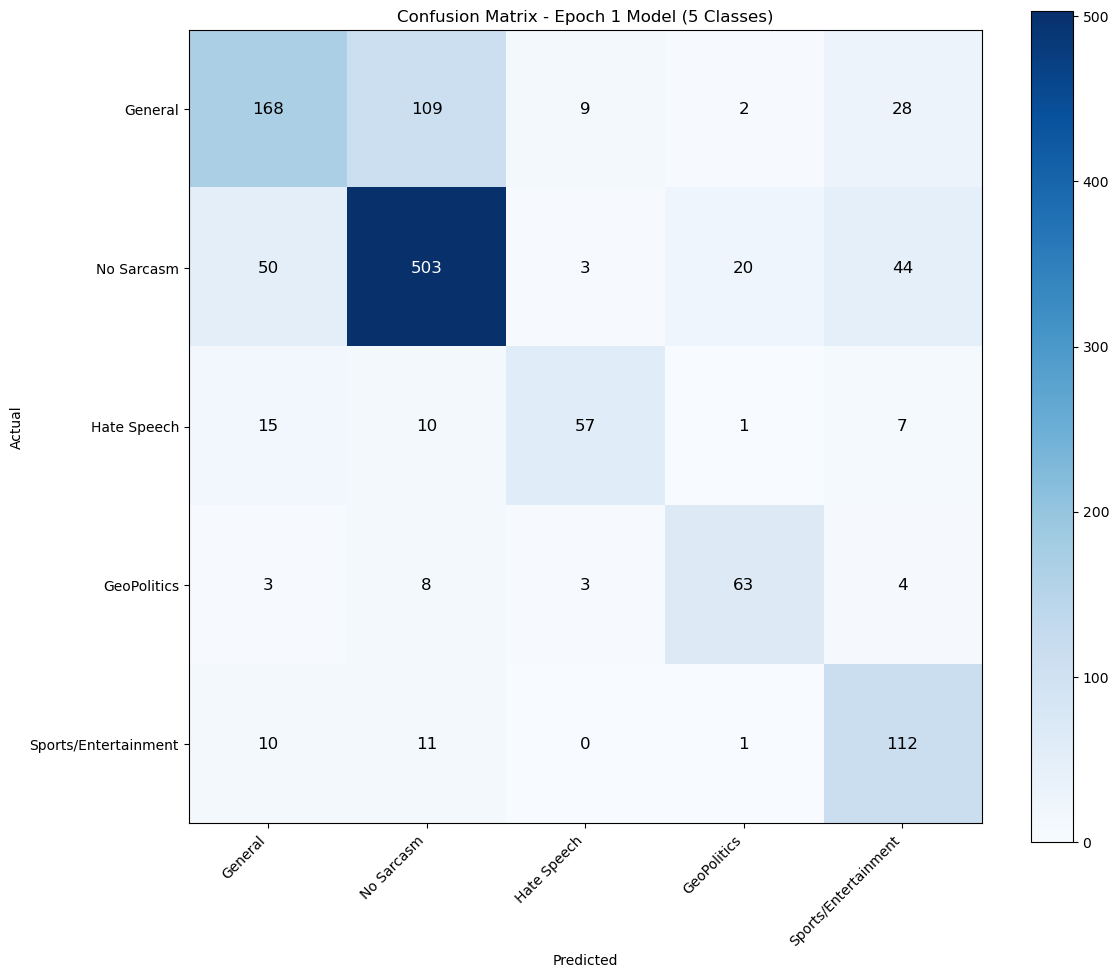

In [ ]:
cm, accuracy, predict = evaluate_epoch_model_with_confusion_matrix(1, test_df=test_df)